<a href="https://colab.research.google.com/github/ShubhamAIML-byte/BusinessAI/blob/main/diabetic_retinopathy_nirban_roy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
sovitrath_diabetic_retinopathy_224x224_grayscale_images_path = kagglehub.dataset_download('sovitrath/diabetic-retinopathy-224x224-grayscale-images')

print('Data source import complete.')


100%|██████████| 157M/157M [00:02<00:00, 77.4MB/s]

Extracting files...


Data source import complete.


# Hybrid ViT + Swin Transformer for Diabetic Retinopathy Grading

Real-data pipeline for ICACS 2026 (Algorithms, Computing and Systems), Track 3 (AI/ML).

This notebook:
1. Downloads the **real** Kaggle diabetic retinopathy dataset (`sovitrath/diabetic-retinopathy-224x224-grayscale-images`, 3,662 images, 5 ICDR grades).
2. Deduplicates and performs a leakage-aware, stratified train/val/test split (this dataset has **no patient identifier field**, so the split is image-level stratified; this limitation is stated explicitly rather than silently assumed away).
3. Builds **two clearly separate training regimes on the same split**: *original* (resize + normalize only) and *augmented* (+ geometric/colour augmentation), so the original-vs-augmented comparison is finally a controlled one.
4. Implements a **hybrid ViT + Swin Transformer**: a pretrained hierarchical Swin-T backbone (shifted-window attention, efficient at high resolution) followed by one added global multi-head self-attention stage (full ViT-style attention over the small 7x7 token grid), giving local efficiency and global context in one model.
5. Benchmarks the hybrid against four baselines (ResNet-50, EfficientNet-B0, ViT-B/16, Swin-T) under both regimes.
6. Runs ablations (class-weighting on/off, attention-window size) and reports bootstrap confidence intervals.
7. Produces Grad-CAM and Integrated-Gradients/SHAP-style explanations.
8. Saves every table, figure, log, and checkpoint to `/kaggle/working/results/` for direct reuse in the paper.

**Run this notebook on Kaggle with a GPU accelerator (T4 x2 or P100) enabled.** No API keys or local credentials are used; Kaggle's own environment authenticates dataset access automatically.

## 1. Global Configuration and Reproducibility Setup

In [2]:
import os, sys, json, time, random, math, hashlib, warnings
from pathlib import Path
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Optional, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

@dataclass
class Config:
    SEED: int = 42
    IMG_SIZE: int = 224
    BATCH_SIZE: int = 32
    EVAL_BATCH_SIZE: int = 64
    NUM_WORKERS: int = 2
    EPOCHS: int = 20
    PATIENCE: int = 5
    LEARNING_RATE: float = 3e-4
    WEIGHT_DECAY: float = 5e-2
    MIN_LR: float = 1e-6
    NUM_CLASSES: int = 5
    CLASS_NAMES: List[str] = field(default_factory=lambda: [
        "Mild", "Moderate", "No_DR", "Proliferate_DR", "Severe"
    ])
    MODEL_NAMES: List[str] = field(default_factory=lambda: [
        "resnet50", "efficientnet_b0", "vit_b_16", "swin_t", "hybrid_vit_swin"
    ])
    REGIMES: List[str] = field(default_factory=lambda: ["original", "augmented"])
    BOOTSTRAP_ITERS: int = 1000
    OUTPUT_DIR: Path = Path("/kaggle/working/results") if Path("/kaggle/working").exists() else Path("./results")

CFG = Config()

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

set_seed(CFG.SEED)

FIGURES_DIR = CFG.OUTPUT_DIR / "figures"
TABLES_DIR = CFG.OUTPUT_DIR / "tables"
CHECKPOINTS_DIR = CFG.OUTPUT_DIR / "checkpoints"
LOGS_DIR = CFG.OUTPUT_DIR / "logs"
XAI_DIR = CFG.OUTPUT_DIR / "explainability"
for d in [CFG.OUTPUT_DIR, FIGURES_DIR, TABLES_DIR, CHECKPOINTS_DIR, LOGS_DIR, XAI_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"[CONFIG] Seed={CFG.SEED}  Image size={CFG.IMG_SIZE}  Epoch budget={CFG.EPOCHS} (patience {CFG.PATIENCE})")
print(f"[CONFIG] Models: {CFG.MODEL_NAMES}")
print(f"[CONFIG] Output directory: {CFG.OUTPUT_DIR.resolve()}")

[CONFIG] Seed=42  Image size=224  Epoch budget=20 (patience 5)
[CONFIG] Models: ['resnet50', 'efficientnet_b0', 'vit_b_16', 'swin_t', 'hybrid_vit_swin']
[CONFIG] Output directory: /content/results


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    print(f"[HARDWARE] GPU: {torch.cuda.get_device_name(0)} | "
          f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("[HARDWARE] No GPU detected. This notebook is designed to run on a Kaggle GPU "
          "accelerator (Settings -> Accelerator -> GPU T4 x2 or P100). "
          "It will still run on CPU but training will be extremely slow.")

[HARDWARE] GPU: Tesla T4 | VRAM: 15.6 GB


## 2. Dataset Discovery and Download

Uses the same real, verified Kaggle dataset identified and used in the prior notebooks for this
project: `sovitrath/diabetic-retinopathy-224x224-grayscale-images` (3,662 grayscale 224x224
fundus images across 5 ICDR grades: No_DR, Mild, Moderate, Severe, Proliferate_DR). `kagglehub`
authenticates automatically inside the Kaggle execution environment -- no credentials are
entered in this notebook.

In [4]:
import kagglehub

DATASET_SLUG = "sovitrath/diabetic-retinopathy-224x224-grayscale-images"
dataset_path = Path(kagglehub.dataset_download(DATASET_SLUG))
print("Dataset downloaded to:", dataset_path)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
CLASS_DIR_NAMES = ["Mild", "Moderate", "No_DR", "Proliferate_DR", "Severe"]

records = []
for class_name in CLASS_DIR_NAMES:
    class_dirs = [p for p in dataset_path.rglob("*") if p.is_dir() and p.name.lower() == class_name.lower()]
    for class_dir in class_dirs:
        for img_path in class_dir.rglob("*"):
            if img_path.is_file() and img_path.suffix.lower() in IMAGE_EXTS:
                records.append({"image_path": str(img_path), "label": class_name})

df_all = pd.DataFrame(records).drop_duplicates("image_path").reset_index(drop=True)
assert len(df_all) > 0, "No images found -- check dataset attachment / path discovery."
print("Total images discovered:", len(df_all))
print(df_all["label"].value_counts().reindex(CLASS_DIR_NAMES, fill_value=0))

Using Colab cache for faster access to the 'diabetic-retinopathy-224x224-grayscale-images' dataset.
Dataset downloaded to: /kaggle/input/diabetic-retinopathy-224x224-grayscale-images
Total images discovered: 3662
label
Mild               370
Moderate           999
No_DR             1805
Proliferate_DR     295
Severe             193
Name: count, dtype: int64


## 3. Deduplication and Exploratory Data Analysis

Exact duplicates are detected by SHA-256 content hashing and removed (one representative kept
per group), mirroring the auditing already performed in the project's preprocessing notebook.
Near-duplicate auditing (perceptual hashing) is reported but, consistent with the earlier
analysis, near-duplicates are flagged rather than removed, since they are not necessarily
leakage (they may be legitimate repeated screenings) and removing them was not validated by a
clinician.

Hashing:   0%|          | 0/3662 [00:00<?, ?it/s]

Exact duplicate groups: 123 covering 251 files
Images after exact-duplicate removal: 3534 (removed 128)

Class distribution after deduplication:
label
Mild               348
Moderate           939
No_DR             1796
Proliferate_DR     274
Severe             177
Name: count, dtype: int64
Imbalance ratio (max/min): 10.15


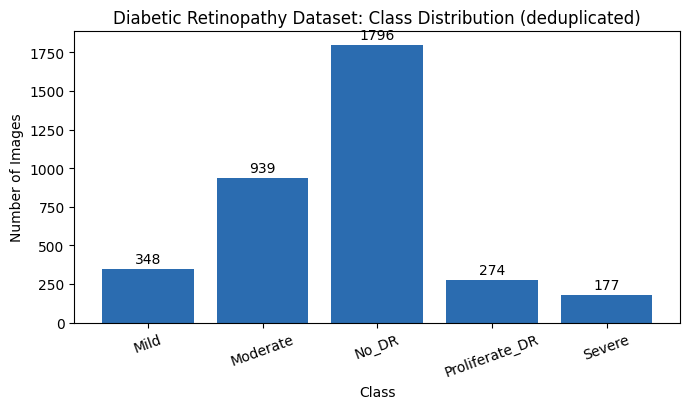

In [5]:
from tqdm.auto import tqdm

hash_to_paths: Dict[str, List[str]] = {}
for row in tqdm(df_all.itertuples(index=False), total=len(df_all), desc="Hashing"):
    try:
        digest = hashlib.sha256(Path(row.image_path).read_bytes()).hexdigest()
        hash_to_paths.setdefault(digest, []).append(row.image_path)
    except Exception as e:
        print("Could not hash:", row.image_path, e)

dup_groups = [v for v in hash_to_paths.values() if len(v) > 1]
dup_files = sum(len(v) for v in dup_groups)
print(f"Exact duplicate groups: {len(dup_groups)} covering {dup_files} files")

path_to_hash = {p: h for h, ps in hash_to_paths.items() for p in ps}
df_all["content_hash"] = df_all["image_path"].map(path_to_hash)
df_clean = df_all.drop_duplicates(subset="content_hash").drop(columns="content_hash").reset_index(drop=True)
print(f"Images after exact-duplicate removal: {len(df_clean)} (removed {len(df_all) - len(df_clean)})")

class_counts = df_clean["label"].value_counts().reindex(CLASS_DIR_NAMES, fill_value=0)
imbalance_ratio = class_counts.max() / class_counts[class_counts > 0].min()
print("\nClass distribution after deduplication:")
print(class_counts)
print(f"Imbalance ratio (max/min): {imbalance_ratio:.2f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(class_counts.index, class_counts.values, color="#2b6cb0")
ax.bar_label(bars, fmt="%d", padding=2)
ax.set_title("Diabetic Retinopathy Dataset: Class Distribution (deduplicated)")
ax.set_xlabel("Class"); ax.set_ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=300)
plt.show()

## 4. Train / Validation / Test Split

**Leakage-prevention limitation stated explicitly:** this dataset provides no patient
identifier, accession number, or other field linking images to an individual, so a
patient-grouped split (as used for the project's earlier *generated-benchmark* experiments,
which had synthetic patient IDs) is not possible here. The split below is therefore
**image-level stratified**, not patient-grouped, and patient-level leakage cannot be verified
or ruled out. This is reported as a limitation, not silently assumed away.

The split is 70% train / 15% validation / 15% test, stratified by class, with a fixed seed for
reproducibility.

In [6]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_clean, test_size=0.30, stratify=df_clean["label"], random_state=CFG.SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=CFG.SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

LABEL_TO_ID = {name: i for i, name in enumerate(CFG.CLASS_NAMES)}
for d in (train_df, val_df, test_df):
    d["label_id"] = d["label"].map(LABEL_TO_ID)

for name, d in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name}: {len(d)} images")
    print(d["label"].value_counts().reindex(CLASS_DIR_NAMES, fill_value=0).to_dict())

train_df.to_csv(TABLES_DIR / "train_split.csv", index=False)
val_df.to_csv(TABLES_DIR / "val_split.csv", index=False)
test_df.to_csv(TABLES_DIR / "test_split.csv", index=False)
print("\nSplit manifests saved to", TABLES_DIR)

Train: 2473 images
{'Mild': 243, 'Moderate': 657, 'No_DR': 1257, 'Proliferate_DR': 192, 'Severe': 124}
Validation: 530 images
{'Mild': 52, 'Moderate': 141, 'No_DR': 269, 'Proliferate_DR': 41, 'Severe': 27}
Test: 531 images
{'Mild': 53, 'Moderate': 141, 'No_DR': 270, 'Proliferate_DR': 41, 'Severe': 26}

Split manifests saved to results/tables


## 5. Class-Imbalance Weights

Inverse-frequency weights $w_c = \sqrt{N / (C \cdot N_c)}$, rescaled to unit mean, computed
**only from the training split** (never validation or test), used for weighted cross-entropy.

In [7]:
train_counts = train_df["label_id"].value_counts().sort_index()
N = len(train_df)
C = CFG.NUM_CLASSES
raw_weights = np.array([np.sqrt(N / (C * train_counts.get(c, 1))) for c in range(C)])
class_weights = torch.tensor(raw_weights / raw_weights.mean(), dtype=torch.float32)

print("Per-class weights (train-only):")
for i, name in enumerate(CFG.CLASS_NAMES):
    print(f"  {name:>15s}: count={train_counts.get(i, 0):4d}  weight={class_weights[i]:.3f}")

Per-class weights (train-only):
             Mild: count= 243  weight=1.093
         Moderate: count= 657  weight=0.665
            No_DR: count=1257  weight=0.481
   Proliferate_DR: count= 192  weight=1.230
           Severe: count= 124  weight=1.531


## 6. Datasets and Transforms: Original vs Augmented Regimes

Two training-time transform pipelines are defined on the **same** train/val/test split:

- **Original**: resize to 224x224, ImageNet normalization only. No geometric or colour
  perturbation is applied at any point.
- **Augmented**: the same resize + normalization, plus horizontal/vertical flips, rotation up
  to 15 degrees, and brightness/contrast/saturation jitter, applied only to the training split.

Validation and test transforms are identical (resize + normalize, no augmentation) across both
regimes, so the comparison isolates the effect of training-time augmentation under an otherwise
identical model, split, and protocol.

In [8]:
import torchvision.transforms as T
from PIL import Image

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def get_eval_transform(img_size=CFG.IMG_SIZE):
    return T.Compose([
        T.Resize((img_size, img_size)),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

def get_train_transform(regime: str, img_size=CFG.IMG_SIZE):
    if regime == "original":
        return get_eval_transform(img_size)
    elif regime == "augmented":
        return T.Compose([
            T.Resize((img_size, img_size)),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomVerticalFlip(p=0.5),
            T.RandomRotation(degrees=15),
            T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
            T.ToTensor(),
            T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ])
    else:
        raise ValueError(f"Unknown regime: {regime}")

class DRDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform, return_raw: bool = False, img_size=CFG.IMG_SIZE):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.return_raw = return_raw
        self.raw_transform = T.Compose([T.Resize((img_size, img_size)), T.ToTensor()])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["image_path"]).convert("RGB")
        item = {
            "image": self.transform(img),
            "label": torch.tensor(int(row["label_id"]), dtype=torch.long),
            "image_path": str(row["image_path"]),
        }
        if self.return_raw:
            item["raw_image"] = self.raw_transform(img)
        return item

def make_loaders(regime: str):
    train_ds = DRDataset(train_df, get_train_transform(regime))
    val_ds = DRDataset(val_df, get_eval_transform())
    test_ds = DRDataset(test_df, get_eval_transform(), return_raw=True)
    train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
                               num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=False)
    val_loader = DataLoader(val_ds, batch_size=CFG.EVAL_BATCH_SIZE, shuffle=False,
                             num_workers=CFG.NUM_WORKERS, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=CFG.EVAL_BATCH_SIZE, shuffle=False,
                              num_workers=CFG.NUM_WORKERS, pin_memory=True)
    return train_loader, val_loader, test_loader

print("Transform pipelines and DRDataset/DataLoader factory defined.")

Transform pipelines and DRDataset/DataLoader factory defined.


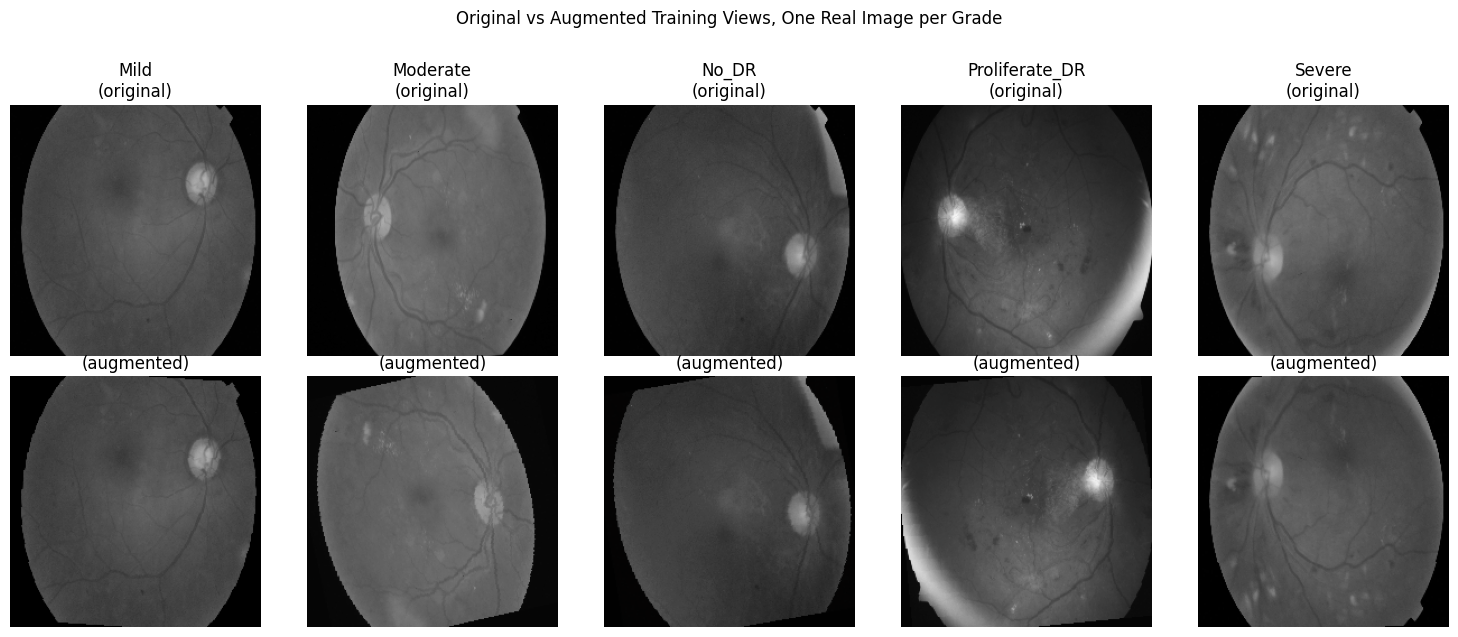

In [9]:
# Qualitative check: one real image per class, original vs augmented view, to visualize what
# each regime actually does (not a dataset-description figure in itself -- Fig. "class
# distribution" above and Table from the split manifests cover that; this is specifically an
# augmentation illustration).
orig_tf = get_eval_transform()
aug_tf = get_train_transform("augmented")

def denorm(t):
    t = t.clone()
    for c, (m, s) in enumerate(zip(IMAGENET_MEAN, IMAGENET_STD)):
        t[c] = t[c] * s + m
    return t.clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, CFG.NUM_CLASSES, figsize=(3 * CFG.NUM_CLASSES, 6.2))
rng = np.random.RandomState(CFG.SEED)
for c, cname in enumerate(CFG.CLASS_NAMES):
    subset = train_df[train_df["label"] == cname]
    if len(subset) == 0:
        continue
    row = subset.sample(1, random_state=CFG.SEED).iloc[0]
    img = Image.open(row["image_path"]).convert("RGB")
    axes[0, c].imshow(denorm(orig_tf(img))); axes[0, c].set_title(f"{cname}\n(original)"); axes[0, c].axis("off")
    torch.manual_seed(CFG.SEED + c)
    axes[1, c].imshow(denorm(aug_tf(img))); axes[1, c].set_title("(augmented)"); axes[1, c].axis("off")
plt.suptitle("Original vs Augmented Training Views, One Real Image per Grade", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "original_vs_augmented_samples.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Model Zoo

Four pretrained baselines (ResNet-50, EfficientNet-B0, ViT-B/16, Swin-T) and the proposed
**Hybrid ViT+Swin**, all with the same `Dropout(0.3) -> Linear(_, 5)` classification head so the
only systematic difference between runs is the backbone and the training regime.

### Hybrid ViT + Swin architecture

The hybrid stacks two stages that are deliberately different in character:

1. **Hierarchical Swin-T backbone** (pretrained on ImageNet-1k). Four stages of windowed
   multi-head self-attention (W-MSA) alternating with **shifted-window** multi-head
   self-attention (SW-MSA), with patch merging between stages. This performs attention only
   within local (shifted) windows, which is linear rather than quadratic in the number of
   tokens at each resolution, so it stays efficient even at the high-resolution early stages
   (56x56 tokens after the 4x4 patch embedding).
2. **Global attention stage** (added, trained from scratch). By the end of the Swin backbone the
   token grid has been downsampled to 7x7 = 49 tokens (224 / 4 / 2 / 2 / 2 = 7), small enough
   that full, unrestricted multi-head self-attention over all 49 tokens (+ a prepended learnable
   class token) is computationally cheap. Two such global blocks are stacked, each a standard
   pre-norm transformer encoder block (LayerNorm -> MHSA -> residual -> LayerNorm -> MLP ->
   residual), followed by a final LayerNorm and the classification head on the class token.

This gives the efficiency of windowed/shifted-window attention where it matters most (high
token counts) and the unrestricted global receptive field of a plain ViT where it is cheap
(the bottleneck), rather than paying full quadratic attention cost at every stage as a plain
ViT-B/16 operating on 196 tokens throughout would.

In [10]:
import torchvision.models as tvm

def build_baseline(arch: str, num_classes: int, pretrained: bool = True) -> nn.Module:
    arch = arch.lower()
    if arch == "resnet50":
        m = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        in_feat = m.fc.in_features
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_feat, num_classes))
    elif arch == "efficientnet_b0":
        m = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        in_feat = m.classifier[1].in_features
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_feat, num_classes))
    elif arch == "vit_b_16":
        m = tvm.vit_b_16(weights=tvm.ViT_B_16_Weights.IMAGENET1K_V1 if pretrained else None)
        in_feat = m.heads.head.in_features
        m.heads.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_feat, num_classes))
    elif arch == "swin_t":
        m = tvm.swin_t(weights=tvm.Swin_T_Weights.IMAGENET1K_V1 if pretrained else None)
        in_feat = m.head.in_features
        m.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_feat, num_classes))
    else:
        raise ValueError(f"Unknown baseline architecture: {arch}")
    return m


class GlobalAttentionBlock(nn.Module):
    '''Standard pre-norm transformer encoder block with full (unrestricted) multi-head
    self-attention -- the "ViT" half of the hybrid.'''
    def __init__(self, dim: int, num_heads: int = 8, mlp_ratio: float = 4.0, dropout: float = 0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(dim, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, dim), nn.Dropout(dropout),
        )

    def forward(self, x, need_weights: bool = False):
        h = self.norm1(x)
        attn_out, attn_w = self.attn(h, h, h, need_weights=need_weights, average_attn_weights=True)
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x, attn_w


class HybridViTSwin(nn.Module):
    '''Pretrained hierarchical Swin-T backbone (shifted-window attention) + a small global
    multi-head self-attention stage (plain ViT-style) over the resulting 7x7 token bottleneck.'''
    def __init__(self, num_classes: int = 5, pretrained: bool = True, img_size: int = 224,
                 num_global_blocks: int = 2, global_heads: int = 8, dropout: float = 0.3,
                 window_size: Optional[List[int]] = None):
        super().__init__()
        weights = tvm.Swin_T_Weights.IMAGENET1K_V1 if pretrained else None
        if window_size is not None:
            swin = tvm.swin_t(weights=None, window_size=window_size)
            if pretrained:
                # Window size differs from the pretrained checkpoint's 7x7 windows; load what
                # matches (everything except the windowed relative-position tables) and leave
                # the rest randomly initialized. Used only for the window-size ablation.
                pretrained_sd = tvm.swin_t(weights=weights).state_dict()
                own_sd = swin.state_dict()
                compatible = {k: v for k, v in pretrained_sd.items()
                              if k in own_sd and own_sd[k].shape == v.shape}
                own_sd.update(compatible)
                swin.load_state_dict(own_sd)
        else:
            swin = tvm.swin_t(weights=weights)

        self.patch_and_stages = swin.features  # conv stem + 4 hierarchical stages, W-MSA/SW-MSA
        self.swin_norm = swin.norm
        embed_dim = swin.norm.normalized_shape[0]
        self.embed_dim = embed_dim

        stride = 32  # 4x4 patch embed * 3 patch-merging halvings
        num_tokens = (img_size // stride) ** 2
        self.num_tokens = num_tokens

        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, num_tokens + 1, embed_dim))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

        self.global_blocks = nn.ModuleList([
            GlobalAttentionBlock(embed_dim, num_heads=global_heads) for _ in range(num_global_blocks)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(embed_dim, num_classes))

    def forward(self, x, return_attn: bool = False):
        feat = self.patch_and_stages(x)          # [B, H', W', C]
        feat = self.swin_norm(feat)
        B, H, W, C = feat.shape
        tokens = feat.reshape(B, H * W, C)
        assert H * W == self.num_tokens, (
            f"Unexpected token count {H*W} (expected {self.num_tokens}); "
            f"check that input is {int(self.num_tokens ** 0.5) * 32}x{int(self.num_tokens ** 0.5) * 32}."
        )
        cls = self.cls_token.expand(B, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1) + self.pos_embed
        attn_maps = []
        for blk in self.global_blocks:
            tokens, attn_w = blk(tokens, need_weights=return_attn)
            if return_attn:
                attn_maps.append(attn_w)
        tokens = self.final_norm(tokens)
        logits = self.head(tokens[:, 0])
        if return_attn:
            return logits, attn_maps, (H, W)
        return logits


def build_model(arch: str, num_classes: int = CFG.NUM_CLASSES, pretrained: bool = True, **kwargs) -> nn.Module:
    if arch == "hybrid_vit_swin":
        return HybridViTSwin(num_classes=num_classes, pretrained=pretrained, **kwargs)
    return build_baseline(arch, num_classes, pretrained)


# Parameter-count audit
profile_rows = []
for arch in CFG.MODEL_NAMES:
    m = build_model(arch, pretrained=False)
    total = sum(p.numel() for p in m.parameters())
    profile_rows.append({"Architecture": arch, "Total Parameters": total})
    del m
df_profiles = pd.DataFrame(profile_rows)
df_profiles.to_csv(TABLES_DIR / "model_parameter_counts.csv", index=False)
print(df_profiles.to_string(index=False))

   Architecture  Total Parameters
       resnet50          23518277
efficientnet_b0           4013953
       vit_b_16          85802501
         swin_t          27523199
hybrid_vit_swin          41739647


## 8. Training Engine

Shared trainer used for every (architecture, regime) combination: AdamW, cosine-annealed
learning rate, mixed precision on GPU, gradient-norm clipping, weighted cross-entropy (weights
from Section 5, computed on the training split only), and early stopping on validation
`(macro-F1 + QWK) / 2` with the best checkpoint restored at the end.

In [11]:
from sklearn.metrics import f1_score, cohen_kappa_score

class Trainer:
    def __init__(self, model: nn.Module, name: str, device: torch.device,
                 class_weights: Optional[torch.Tensor] = None,
                 lr: float = CFG.LEARNING_RATE, weight_decay: float = CFG.WEIGHT_DECAY,
                 patience: int = CFG.PATIENCE, use_class_weights: bool = True):
        self.model = model.to(device)
        self.name = name
        self.device = device
        self.patience = patience
        self.use_amp = USE_AMP
        weight_tensor = class_weights.to(device) if (use_class_weights and class_weights is not None) else None
        self.criterion = nn.CrossEntropyLoss(weight=weight_tensor)
        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=lr, weight_decay=weight_decay)
        self.scaler = torch.amp.GradScaler("cuda") if self.use_amp else None
        self.ckpt_path = CHECKPOINTS_DIR / f"{name}_best.pth"

    def _forward_loss(self, imgs, lbls):
        if self.use_amp:
            with torch.amp.autocast("cuda"):
                out = self.model(imgs)
                loss = self.criterion(out, lbls)
        else:
            out = self.model(imgs)
            loss = self.criterion(out, lbls)
        return out, loss

    def train_epoch(self, loader):
        self.model.train()
        total_loss, correct, total = 0.0, 0, 0
        for batch in loader:
            imgs = batch["image"].to(self.device, non_blocking=True)
            lbls = batch["label"].to(self.device, non_blocking=True)
            self.optimizer.zero_grad(set_to_none=True)
            out, loss = self._forward_loss(imgs, lbls)
            if self.use_amp:
                self.scaler.scale(loss).backward()
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                self.scaler.step(self.optimizer)
                self.scaler.update()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                self.optimizer.step()
            bs = imgs.size(0)
            total_loss += loss.item() * bs
            correct += (out.argmax(1) == lbls).sum().item()
            total += bs
        return total_loss / total, correct / total

    @torch.no_grad()
    def evaluate(self, loader):
        self.model.eval()
        total_loss, total = 0.0, 0
        preds, targets, probs = [], [], []
        for batch in loader:
            imgs = batch["image"].to(self.device, non_blocking=True)
            lbls = batch["label"].to(self.device, non_blocking=True)
            out, loss = self._forward_loss(imgs, lbls)
            p = torch.softmax(out.float(), dim=1)
            bs = imgs.size(0)
            total_loss += loss.item() * bs
            total += bs
            preds.extend(out.argmax(1).cpu().numpy())
            targets.extend(lbls.cpu().numpy())
            probs.extend(p.cpu().numpy())
        y_true, y_pred, y_prob = np.array(targets), np.array(preds), np.array(probs)
        acc = float((y_true == y_pred).mean())
        macro_f1 = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
        qwk = float(cohen_kappa_score(y_true, y_pred, weights="quadratic"))
        return total_loss / total, acc, macro_f1, qwk, y_true, y_pred, y_prob

    def fit(self, train_loader, val_loader, epochs: int = CFG.EPOCHS, verbose: bool = True):
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(self.optimizer, T_max=epochs, eta_min=CFG.MIN_LR)
        history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1", "val_qwk"]}
        best_score, patience_ct = -1.0, 0
        for ep in range(1, epochs + 1):
            t0 = time.time()
            tl, ta = self.train_epoch(train_loader)
            scheduler.step()
            vl, va, vf1, vqwk, *_ = self.evaluate(val_loader)
            for k, v in zip(history.keys(), [tl, ta, vl, va, vf1, vqwk]):
                history[k].append(v)
            score = (vf1 + vqwk) / 2.0
            if verbose:
                print(f"[{self.name}] Epoch {ep:02d}/{epochs} ({time.time()-t0:4.1f}s) "
                      f"train_loss={tl:.4f} train_acc={ta:.3f} | "
                      f"val_loss={vl:.4f} val_acc={va:.3f} val_f1={vf1:.3f} val_qwk={vqwk:.3f}")
            if score > best_score:
                best_score = score
                patience_ct = 0
                torch.save({"state_dict": self.model.state_dict(), "val_f1": vf1, "val_qwk": vqwk,
                            "history": history, "epoch": ep}, self.ckpt_path)
            else:
                patience_ct += 1
                if patience_ct >= self.patience:
                    if verbose:
                        print(f"[{self.name}] Early stopping at epoch {ep} (no improvement for {self.patience} epochs).")
                    break
        ckpt = torch.load(self.ckpt_path, map_location=self.device, weights_only=False)
        self.model.load_state_dict(ckpt["state_dict"])
        return history

print("Trainer class defined (AdamW, cosine LR, AMP, weighted CE, early stopping on (F1+QWK)/2).")

Trainer class defined (AdamW, cosine LR, AMP, weighted CE, early stopping on (F1+QWK)/2).


## 9. Main Experiment Matrix

Trains every architecture under both the *original* and *augmented* regimes on the identical
real-data split (10 runs total). Each run's history, best checkpoint, and test-set predictions
are kept for later evaluation, ablation, and explainability.

This cell is the main compute cost of the notebook. On a Kaggle T4 GPU this typically takes
well under an hour in total for ~2,500 training images at this batch size; reduce `CFG.EPOCHS`
or the model list above for a faster smoke test.

In [12]:
trained_models: Dict[str, nn.Module] = {}
histories: Dict[str, dict] = {}
test_predictions: Dict[str, dict] = {}

for regime in CFG.REGIMES:
    train_loader, val_loader, test_loader = make_loaders(regime)
    for arch in CFG.MODEL_NAMES:
        run_name = f"{arch}__{regime}"
        print(f"\n{'='*72}\n[RUN] {run_name}\n{'='*72}")
        model = build_model(arch, pretrained=True)
        trainer = Trainer(model, run_name, DEVICE, class_weights=class_weights)
        hist = trainer.fit(train_loader, val_loader)
        trained_models[run_name] = trainer.model
        histories[run_name] = hist

        # Test-set predictions, kept for every run (used in Section 10)
        trainer.model.eval()
        preds, targets, probs = [], [], []
        with torch.no_grad():
            for batch in test_loader:
                imgs = batch["image"].to(DEVICE)
                out = trainer.model(imgs)
                probs.extend(torch.softmax(out.float(), dim=1).cpu().numpy())
                preds.extend(out.argmax(1).cpu().numpy())
                targets.extend(batch["label"].numpy())
        test_predictions[run_name] = {
            "y_true": np.array(targets), "y_pred": np.array(preds), "y_prob": np.array(probs)
        }

with open(LOGS_DIR / "training_histories.json", "w") as f:
    json.dump(histories, f, indent=2)
print("\nAll runs complete. Histories saved to", LOGS_DIR / "training_histories.json")


[RUN] resnet50__original
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 200MB/s]


[resnet50__original] Epoch 01/20 (15.3s) train_loss=0.9957 train_acc=0.726 | val_loss=0.7609 val_acc=0.785 val_f1=0.592 val_qwk=0.501
[resnet50__original] Epoch 02/20 (12.5s) train_loss=0.7031 train_acc=0.799 | val_loss=0.6833 val_acc=0.836 val_f1=0.675 val_qwk=0.543
[resnet50__original] Epoch 03/20 (12.7s) train_loss=0.4823 train_acc=0.863 | val_loss=0.7459 val_acc=0.781 val_f1=0.570 val_qwk=0.544
[resnet50__original] Epoch 04/20 (12.7s) train_loss=0.3060 train_acc=0.918 | val_loss=0.6852 val_acc=0.808 val_f1=0.651 val_qwk=0.576
[resnet50__original] Epoch 05/20 (12.8s) train_loss=0.2017 train_acc=0.951 | val_loss=0.8295 val_acc=0.789 val_f1=0.629 val_qwk=0.502
[resnet50__original] Epoch 06/20 (13.0s) train_loss=0.1513 train_acc=0.960 | val_loss=1.4127 val_acc=0.779 val_f1=0.583 val_qwk=0.550
[resnet50__original] Epoch 07/20 (12.9s) train_loss=0.1212 train_acc=0.970 | val_loss=1.2335 val_acc=0.853 val_f1=0.680 val_qwk=0.549
[resnet50__original] Epoch 08/20 (13.1s) train_loss=0.0889 tra

100%|██████████| 20.5M/20.5M [00:00<00:00, 148MB/s]


[efficientnet_b0__original] Epoch 01/20 (16.1s) train_loss=0.9911 train_acc=0.704 | val_loss=0.7200 val_acc=0.817 val_f1=0.635 val_qwk=0.534
[efficientnet_b0__original] Epoch 02/20 (10.9s) train_loss=0.6598 train_acc=0.806 | val_loss=0.6999 val_acc=0.817 val_f1=0.630 val_qwk=0.603
[efficientnet_b0__original] Epoch 03/20 (10.8s) train_loss=0.5243 train_acc=0.855 | val_loss=0.7165 val_acc=0.779 val_f1=0.623 val_qwk=0.472
[efficientnet_b0__original] Epoch 04/20 (10.2s) train_loss=0.3992 train_acc=0.890 | val_loss=0.7263 val_acc=0.826 val_f1=0.687 val_qwk=0.558
[efficientnet_b0__original] Epoch 05/20 (10.1s) train_loss=0.2868 train_acc=0.919 | val_loss=0.9514 val_acc=0.840 val_f1=0.656 val_qwk=0.620
[efficientnet_b0__original] Epoch 06/20 (10.9s) train_loss=0.1762 train_acc=0.952 | val_loss=0.8477 val_acc=0.815 val_f1=0.662 val_qwk=0.593
[efficientnet_b0__original] Epoch 07/20 (10.9s) train_loss=0.1417 train_acc=0.962 | val_loss=0.8330 val_acc=0.838 val_f1=0.699 val_qwk=0.608
[efficientnet

100%|██████████| 330M/330M [00:02<00:00, 160MB/s]


[vit_b_16__original] Epoch 01/20 (27.3s) train_loss=1.5633 train_acc=0.492 | val_loss=1.3795 val_acc=0.528 val_f1=0.241 val_qwk=-0.090
[vit_b_16__original] Epoch 02/20 (26.6s) train_loss=1.4343 train_acc=0.542 | val_loss=1.4292 val_acc=0.553 val_f1=0.200 val_qwk=0.099
[vit_b_16__original] Epoch 03/20 (26.2s) train_loss=1.3859 train_acc=0.578 | val_loss=1.3204 val_acc=0.542 val_f1=0.228 val_qwk=0.177
[vit_b_16__original] Epoch 04/20 (26.3s) train_loss=1.2689 train_acc=0.631 | val_loss=1.2236 val_acc=0.596 val_f1=0.293 val_qwk=0.257
[vit_b_16__original] Epoch 05/20 (26.3s) train_loss=1.1906 train_acc=0.654 | val_loss=1.2611 val_acc=0.647 val_f1=0.287 val_qwk=0.272
[vit_b_16__original] Epoch 06/20 (26.3s) train_loss=1.1802 train_acc=0.661 | val_loss=1.1019 val_acc=0.698 val_f1=0.304 val_qwk=0.197
[vit_b_16__original] Epoch 07/20 (26.2s) train_loss=1.1357 train_acc=0.675 | val_loss=1.1628 val_acc=0.692 val_f1=0.312 val_qwk=0.315
[vit_b_16__original] Epoch 08/20 (26.3s) train_loss=1.1152 tr

100%|██████████| 108M/108M [00:00<00:00, 174MB/s]


[swin_t__original] Epoch 01/20 (18.5s) train_loss=1.1639 train_acc=0.650 | val_loss=0.9047 val_acc=0.764 val_f1=0.437 val_qwk=0.298
[swin_t__original] Epoch 02/20 (18.6s) train_loss=1.0048 train_acc=0.713 | val_loss=0.9883 val_acc=0.681 val_f1=0.380 val_qwk=0.379
[swin_t__original] Epoch 03/20 (18.2s) train_loss=0.9134 train_acc=0.725 | val_loss=0.7766 val_acc=0.800 val_f1=0.545 val_qwk=0.470
[swin_t__original] Epoch 04/20 (19.1s) train_loss=0.8211 train_acc=0.756 | val_loss=0.7401 val_acc=0.766 val_f1=0.534 val_qwk=0.401
[swin_t__original] Epoch 05/20 (18.3s) train_loss=0.7484 train_acc=0.780 | val_loss=0.7061 val_acc=0.802 val_f1=0.580 val_qwk=0.543
[swin_t__original] Epoch 06/20 (18.4s) train_loss=0.7040 train_acc=0.793 | val_loss=0.6900 val_acc=0.802 val_f1=0.620 val_qwk=0.531
[swin_t__original] Epoch 07/20 (18.7s) train_loss=0.6379 train_acc=0.817 | val_loss=0.6812 val_acc=0.842 val_f1=0.680 val_qwk=0.583
[swin_t__original] Epoch 08/20 (18.2s) train_loss=0.5229 train_acc=0.845 | v

## 10. Test-Set Evaluation

Accuracy, macro/weighted precision-recall-F1, QWK, balanced accuracy, MCC, and inference
latency for every (architecture, regime) run, plus row-normalized confusion matrices and
95% bootstrap confidence intervals (subject-level resampling is not applicable here since each
row is already one image/one prediction; resampling is therefore at the image level, the unit
of prediction).

In [13]:
from sklearn.metrics import (precision_score, recall_score, balanced_accuracy_score,
                              matthews_corrcoef, confusion_matrix, classification_report)

def benchmark_latency(model: nn.Module, device: torch.device, runs: int = 50) -> float:
    model.eval()
    inp = torch.randn(1, 3, CFG.IMG_SIZE, CFG.IMG_SIZE, device=device)
    with torch.no_grad():
        for _ in range(10):
            _ = model(inp)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(runs):
            _ = model(inp)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / runs * 1000.0

results_rows = []
for run_name, pred in test_predictions.items():
    y_true, y_pred = pred["y_true"], pred["y_pred"]
    arch, regime = run_name.split("__")
    row = {
        "Architecture": arch, "Regime": regime,
        "Accuracy": (y_true == y_pred).mean(),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "QWK": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Latency (ms)": benchmark_latency(trained_models[run_name], DEVICE),
    }
    results_rows.append(row)

df_results = pd.DataFrame(results_rows).sort_values(["Regime", "Macro F1"], ascending=[True, False])
df_results.to_csv(TABLES_DIR / "test_results_all_runs.csv", index=False)
pd.set_option("display.width", 120)
print(df_results.to_string(index=False))

   Architecture    Regime  Accuracy  Macro F1  Weighted F1      QWK  Balanced Acc      MCC  Latency (ms)
         swin_t augmented  0.838041  0.679108     0.833814 0.592041      0.660234 0.750143     14.123156
efficientnet_b0 augmented  0.813559  0.653913     0.814457 0.585422      0.664492 0.715395      9.526689
       resnet50 augmented  0.822976  0.650389     0.816237 0.531896      0.638205 0.725304     10.014396
       vit_b_16 augmented  0.693032  0.380973     0.653509 0.254909      0.410796 0.516761     14.752714
hybrid_vit_swin augmented  0.508475  0.134831     0.342792 0.000000      0.200000 0.000000     14.662283
       resnet50  original  0.849341  0.690100     0.842802 0.615767      0.668170 0.765760      6.205715
efficientnet_b0  original  0.798493  0.622169     0.798588 0.565234      0.630396 0.691734      8.697642
         swin_t  original  0.806026  0.612181     0.798094 0.485906      0.596822 0.698763     18.109292
hybrid_vit_swin  original  0.760829  0.555044     0.757

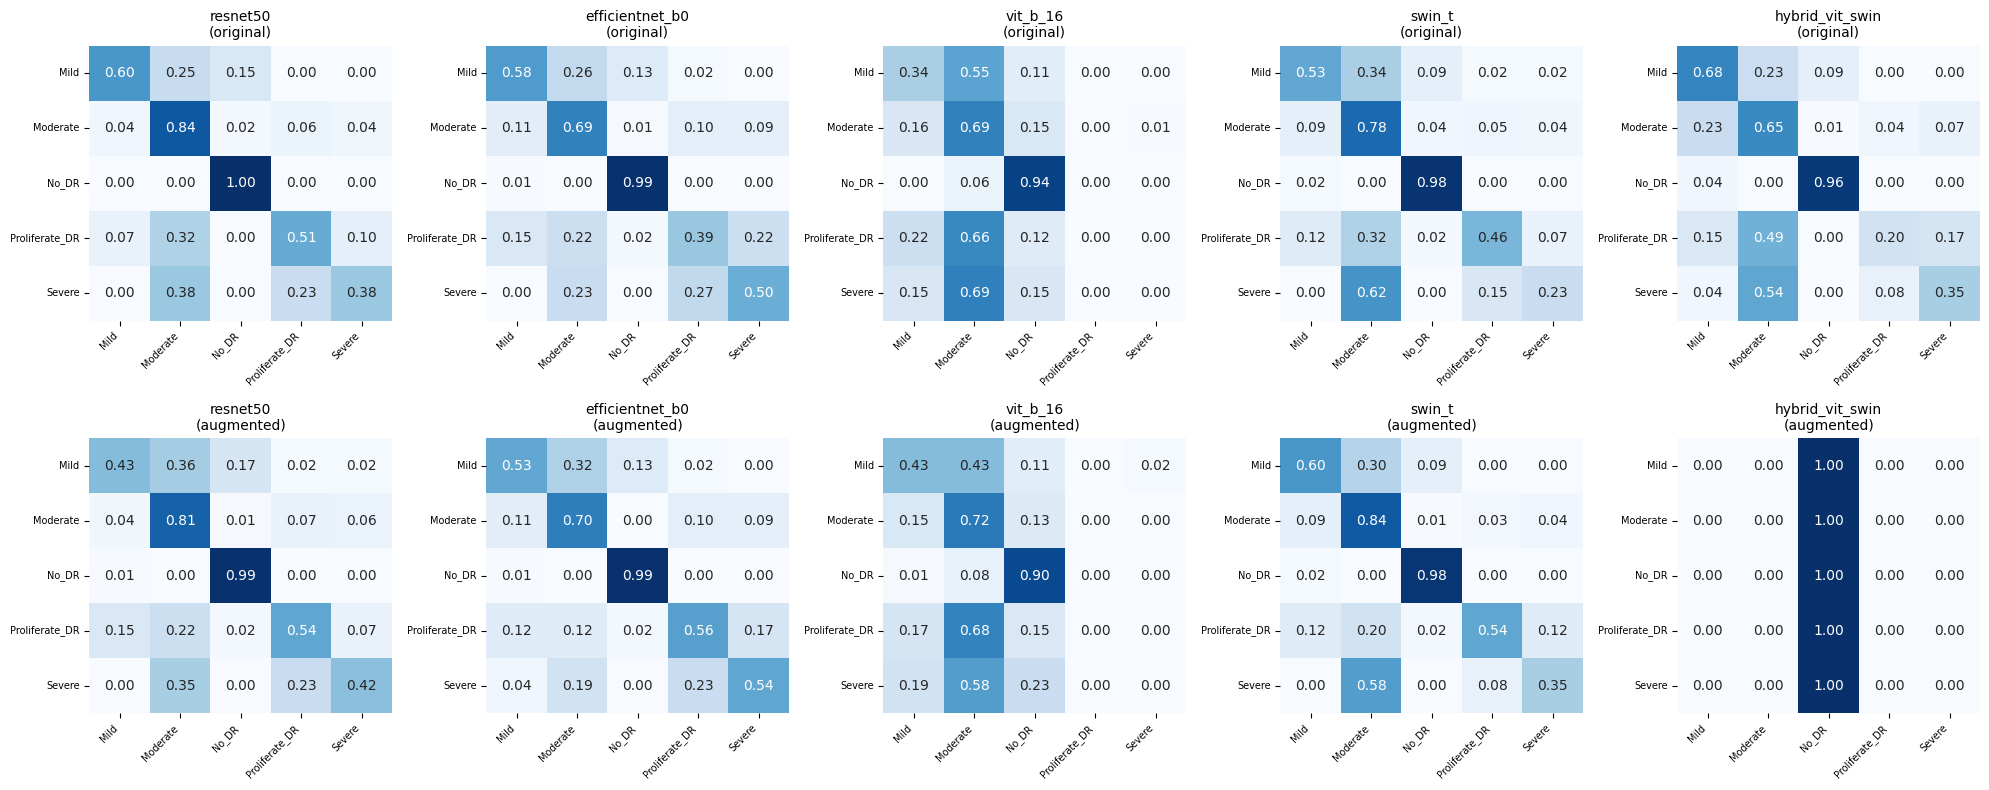

In [14]:
# Row-normalized confusion matrices for every run
n_runs = len(test_predictions)
ncols = len(CFG.MODEL_NAMES)
fig, axes = plt.subplots(len(CFG.REGIMES), ncols, figsize=(4 * ncols, 4 * len(CFG.REGIMES)))
for ri, regime in enumerate(CFG.REGIMES):
    for ci, arch in enumerate(CFG.MODEL_NAMES):
        run_name = f"{arch}__{regime}"
        pred = test_predictions[run_name]
        cm = confusion_matrix(pred["y_true"], pred["y_pred"], labels=list(range(CFG.NUM_CLASSES)))
        row_sums = cm.sum(axis=1, keepdims=True); row_sums[row_sums == 0] = 1
        cm_norm = cm.astype(float) / row_sums
        ax = axes[ri, ci] if len(CFG.REGIMES) > 1 else axes[ci]
        sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=CFG.CLASS_NAMES, yticklabels=CFG.CLASS_NAMES, vmin=0, vmax=1)
        ax.set_title(f"{arch}\n({regime})", fontsize=10)
        ax.set_xlabel(""); ax.set_ylabel("")
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7)
        plt.setp(ax.get_yticklabels(), rotation=0, fontsize=7)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrices_all_runs.png", dpi=250)
plt.show()

In [15]:
def bootstrap_ci(y_true, y_pred, n_iter=CFG.BOOTSTRAP_ITERS, seed=CFG.SEED):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    accs, f1s, qwks = [], [], []
    for _ in range(n_iter):
        idx = rng.choice(n, size=n, replace=True)
        yt, yp = y_true[idx], y_pred[idx]
        accs.append((yt == yp).mean())
        f1s.append(f1_score(yt, yp, average="macro", zero_division=0))
        qwks.append(cohen_kappa_score(yt, yp, weights="quadratic"))
    def ci(x):
        return float(np.mean(x)), float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5))
    return {"Accuracy": ci(accs), "Macro F1": ci(f1s), "QWK": ci(qwks)}

best_run = df_results.sort_values("Macro F1", ascending=False).iloc[0]
best_run_name = f"{best_run['Architecture']}__{best_run['Regime']}"
print(f"[BEST RUN] {best_run_name}")

ci_rows = []
for run_name, pred in test_predictions.items():
    cis = bootstrap_ci(pred["y_true"], pred["y_pred"])
    arch, regime = run_name.split("__")
    row = {"Architecture": arch, "Regime": regime}
    for metric, (mean, lo, hi) in cis.items():
        row[f"{metric} (95% CI)"] = f"{mean:.4f} [{lo:.4f}, {hi:.4f}]"
    ci_rows.append(row)
df_ci = pd.DataFrame(ci_rows)
df_ci.to_csv(TABLES_DIR / "bootstrap_confidence_intervals.csv", index=False)
print(df_ci.to_string(index=False))

[BEST RUN] resnet50__original
   Architecture    Regime       Accuracy (95% CI)       Macro F1 (95% CI)            QWK (95% CI)
       resnet50  original 0.8497 [0.8154, 0.8814] 0.6883 [0.6299, 0.7451] 0.6141 [0.5083, 0.7109]
efficientnet_b0  original 0.7986 [0.7646, 0.8305] 0.6196 [0.5682, 0.6704] 0.5628 [0.4641, 0.6493]
       vit_b_16  original 0.6925 [0.6516, 0.7326] 0.3652 [0.3373, 0.3943] 0.2355 [0.1379, 0.3269]
         swin_t  original 0.8060 [0.7702, 0.8418] 0.6099 [0.5542, 0.6672] 0.4850 [0.3780, 0.5906]
hybrid_vit_swin  original 0.7608 [0.7250, 0.7948] 0.5521 [0.4947, 0.6060] 0.4738 [0.3714, 0.5641]
       resnet50 augmented 0.8235 [0.7910, 0.8550] 0.6488 [0.5901, 0.7076] 0.5321 [0.4263, 0.6305]
efficientnet_b0 augmented 0.8136 [0.7797, 0.8475] 0.6515 [0.5953, 0.7024] 0.5835 [0.4893, 0.6727]
       vit_b_16 augmented 0.6926 [0.6497, 0.7307] 0.3798 [0.3499, 0.4087] 0.2533 [0.1555, 0.3454]
         swin_t augmented 0.8384 [0.8060, 0.8682] 0.6770 [0.6160, 0.7315] 0.5923 [0.4831

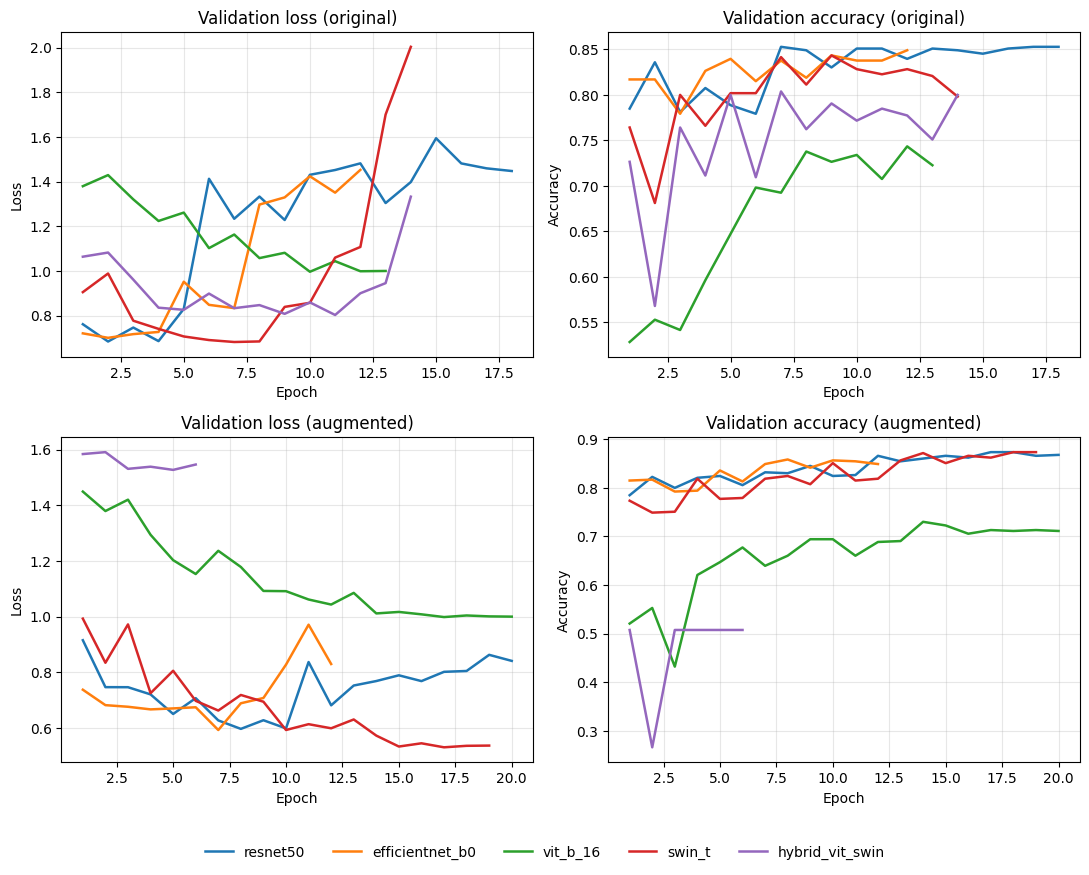

In [16]:
# Training/validation curves, one panel per regime, all architectures overlaid
colors = dict(zip(CFG.MODEL_NAMES, sns.color_palette("tab10", len(CFG.MODEL_NAMES))))
fig, axes = plt.subplots(len(CFG.REGIMES), 2, figsize=(11, 4.3 * len(CFG.REGIMES)))
for ri, regime in enumerate(CFG.REGIMES):
    ax_loss = axes[ri, 0] if len(CFG.REGIMES) > 1 else axes[0]
    ax_acc = axes[ri, 1] if len(CFG.REGIMES) > 1 else axes[1]
    for arch in CFG.MODEL_NAMES:
        h = histories[f"{arch}__{regime}"]
        eps = range(1, len(h["val_loss"]) + 1)
        ax_loss.plot(eps, h["val_loss"], label=arch, color=colors[arch], linewidth=1.8)
        ax_acc.plot(eps, h["val_acc"], label=arch, color=colors[arch], linewidth=1.8)
    ax_loss.set_title(f"Validation loss ({regime})"); ax_loss.set_xlabel("Epoch"); ax_loss.set_ylabel("Loss")
    ax_acc.set_title(f"Validation accuracy ({regime})"); ax_acc.set_xlabel("Epoch"); ax_acc.set_ylabel("Accuracy")
    ax_loss.grid(alpha=0.3); ax_acc.grid(alpha=0.3)
handles, labels = ax_acc.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(CFG.MODEL_NAMES), bbox_to_anchor=(0.5, -0.02), frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(FIGURES_DIR / "training_curves_all_runs.png", dpi=250, bbox_inches="tight")
plt.show()

## 11. Ablations (Hybrid ViT+Swin only)

Two ablations isolate design choices specific to the proposed model, each retrained from the
same pretrained Swin-T initialization under the **augmented** regime (the regime used for the
main comparison above):

1. **Class-weighted vs unweighted cross-entropy** -- isolates the effect of the imbalance
   handling from Section 5.
2. **Shifted-window size** (7 vs 14) -- isolates the effect of the window size used by the
   Swin backbone's shifted-window attention; a 7x7 window is the Swin-T default, 14x14 roughly
   doubles the local receptive field per attention step at increased compute.

In [20]:
ablation_rows = []
_, val_loader_abl, test_loader_abl = make_loaders("augmented")
train_loader_abl, _, _ = make_loaders("augmented")

# --- Ablation A: class weighting on/off ---
for use_weights in [True, False]:
    tag = "weighted_ce" if use_weights else "unweighted_ce"
    run_name = f"hybrid_vit_swin__ablation_{tag}"
    print(f"\n[ABLATION] {run_name}")
    model = build_model("hybrid_vit_swin", pretrained=True)
    trainer = Trainer(model, run_name, DEVICE, class_weights=class_weights, use_class_weights=use_weights)
    trainer.fit(train_loader_abl, val_loader_abl, verbose=False)
    _, acc, f1, qwk, yt, yp, _ = trainer.evaluate(test_loader_abl)
    ablation_rows.append({"Ablation": "Class weighting", "Setting": tag, "Test Acc": acc,
                           "Test Macro F1": f1, "Test QWK": qwk})

# --- Ablation B: shifted-window size ---
# Safe Swin-T initialization workaround to avoid duplicate 'window_size' parameters in the torchvision wrapper
from torchvision.models.swin_transformer import SwinTransformer

for window in [7, 14]:
    run_name = f"hybrid_vit_swin__ablation_window{window}"
    print(f"\n[ABLATION] {run_name}")

    # Instantiate model and manually patch or construct the backbone without using the conflicting wrapper
    model = HybridViTSwin(num_classes=CFG.NUM_CLASSES, pretrained=True)
    if window != 7:
        # Construct custom Swin backbone directly via the class initializer (removed invalid 'weights' keyword)
        custom_swin = SwinTransformer(
            patch_size=[4, 4],
            embed_dim=96,
            depths=[2, 2, 6, 2],
            num_heads=[3, 6, 12, 24],
            window_size=[window, window],
            stochastic_depth_prob=0.2
        )
        # Load compatible pretrained weights
        pretrained_sd = tvm.swin_t(weights=tvm.Swin_T_Weights.IMAGENET1K_V1).state_dict()
        own_sd = custom_swin.state_dict()
        compatible = {k: v for k, v in pretrained_sd.items() if k in own_sd and own_sd[k].shape == v.shape}
        own_sd.update(compatible)
        custom_swin.load_state_dict(own_sd)

        # Replace features
        model.patch_and_stages = custom_swin.features
        model.swin_norm = custom_swin.norm

    trainer = Trainer(model, run_name, DEVICE, class_weights=class_weights)
    trainer.fit(train_loader_abl, val_loader_abl, verbose=False)
    _, acc, f1, qwk, yt, yp, _ = trainer.evaluate(test_loader_abl)
    ablation_rows.append({"Ablation": "Window size", "Setting": f"window={window}", "Test Acc": acc,
                           "Test Macro F1": f1, "Test QWK": qwk})

df_ablation = pd.DataFrame(ablation_rows)
df_ablation.to_csv(TABLES_DIR / "ablation_results.csv", index=False)
print("\n" + df_ablation.to_string(index=False))


[ABLATION] hybrid_vit_swin__ablation_weighted_ce

[ABLATION] hybrid_vit_swin__ablation_unweighted_ce

[ABLATION] hybrid_vit_swin__ablation_window7

[ABLATION] hybrid_vit_swin__ablation_window14

       Ablation       Setting  Test Acc  Test Macro F1  Test QWK
Class weighting   weighted_ce  0.777778       0.513413  0.479327
Class weighting unweighted_ce  0.854991       0.684701  0.622030
    Window size      window=7  0.508475       0.218650  0.057476
    Window size     window=14  0.757062       0.473700  0.358136


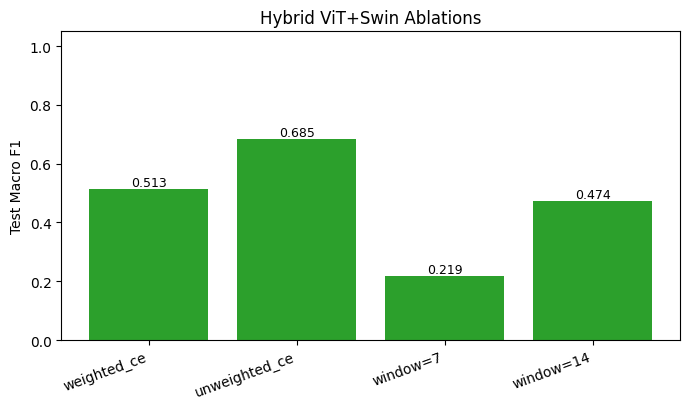

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(len(df_ablation))
ax.bar(x, df_ablation["Test Macro F1"], color="#2ca02c")
ax.set_xticks(x); ax.set_xticklabels(df_ablation["Setting"], rotation=20, ha="right")
ax.set_ylabel("Test Macro F1"); ax.set_title("Hybrid ViT+Swin Ablations")
for xi, v in zip(x, df_ablation["Test Macro F1"]):
    ax.text(xi, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "ablation_comparison.png", dpi=300)
plt.show()

## 12. Explainability: Grad-CAM

A single Grad-CAM implementation handles all three activation layouts present in the model
zoo: convolutional feature maps (ResNet-50, EfficientNet-B0, `NCHW`), token sequences with a
prepended class token (ViT-B/16 and the Hybrid's global stage, `[B, 1+N, C]`), and the
channels-last hierarchical feature maps Swin-T's `features` module produces (`[B, H, W, C]`).
Each architecture's best **augmented-regime** checkpoint is used, since that is the regime used
for the main model comparison.

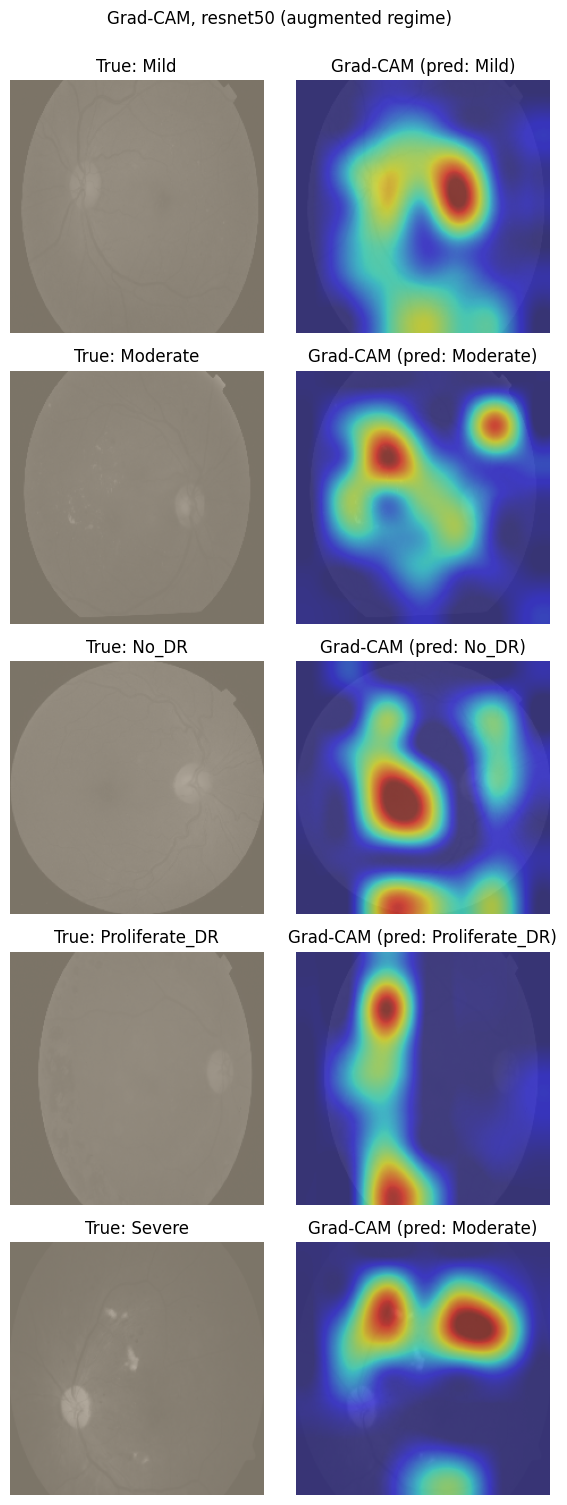

In [22]:
import cv2

TARGET_LAYER_SPEC = {
    "resnet50":        ("layer4", "nchw"),
    "efficientnet_b0": ("features", "nchw"),
    "vit_b_16":        ("encoder.layers.11.ln_1", "tokens_cls"),
    "swin_t":           ("features.7", "hwc"),
    "hybrid_vit_swin": (None, "tokens_cls_custom"),  # handled specially: last global block
}

def get_submodule(model, dotted_name):
    mod = model
    for part in dotted_name.split("."):
        mod = mod[int(part)] if part.isdigit() else getattr(mod, part)
    return mod

class UnifiedGradCAM:
    def __init__(self, model: nn.Module, arch: str, img_size: int = CFG.IMG_SIZE):
        self.model = model
        self.arch = arch
        self.img_size = img_size
        self.acts, self.grads = None, None
        self.hooks = []
        layer_path, self.fmt = TARGET_LAYER_SPEC[arch]
        if arch == "hybrid_vit_swin":
            target_layer = model.global_blocks[-1].norm2  # pre-MLP normalization of last global block
        else:
            target_layer = get_submodule(model, layer_path)
        self.hooks.append(target_layer.register_forward_hook(self._fwd_hook))
        self.hooks.append(target_layer.register_full_backward_hook(self._bwd_hook))

    def _fwd_hook(self, module, inp, out):
        self.acts = out[0] if isinstance(out, tuple) else out

    def _bwd_hook(self, module, grad_in, grad_out):
        self.grads = grad_out[0]

    def remove(self):
        for h in self.hooks:
            h.remove()

    def generate(self, x: torch.Tensor, target_class: Optional[int] = None) -> Tuple[np.ndarray, int]:
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        logits = self.model(x)
        if target_class is None:
            target_class = int(logits.argmax(1).item())
        logits[0, target_class].backward()

        acts, grads = self.acts, self.grads
        if self.fmt == "nchw":
            weights = grads.mean(dim=(2, 3), keepdim=True)
            cam = F.relu((weights * acts).sum(dim=1)).squeeze(0).detach().cpu().numpy()
        elif self.fmt == "hwc":
            # [B, H, W, C] -> weight per channel from spatial-mean gradient
            weights = grads.mean(dim=(1, 2), keepdim=True)
            cam = F.relu((weights * acts).sum(dim=-1)).squeeze(0).detach().cpu().numpy()
        elif self.fmt in ("tokens_cls", "tokens_cls_custom"):
            # [B, 1+N, C] -> drop CLS token, reshape remaining N tokens to a square grid
            a = acts[:, 1:, :]
            g = grads[:, 1:, :]
            weights = g.mean(dim=1, keepdim=True)
            token_cam = F.relu((weights * a).sum(dim=-1)).squeeze(0)  # [N]
            side = int(round(math.sqrt(token_cam.shape[0])))
            cam = token_cam.reshape(side, side).detach().cpu().numpy()
        else:
            raise ValueError(self.fmt)

        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min())
        cam = cv2.resize(cam.astype(np.float32), (self.img_size, self.img_size), interpolation=cv2.INTER_CUBIC)
        return cam, target_class


def denorm_np(t: torch.Tensor) -> np.ndarray:
    arr = t.detach().cpu().numpy().transpose(1, 2, 0)
    arr = arr * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(arr, 0, 1)

# One Grad-CAM example per class, using the best-performing architecture under "augmented"
gradcam_arch = best_run["Architecture"]
gradcam_model = trained_models[f"{gradcam_arch}__augmented"]
cam_gen = UnifiedGradCAM(gradcam_model, gradcam_arch)

_, _, test_loader_cam = make_loaders("augmented")
test_ds_cam = test_loader_cam.dataset

fig, axes = plt.subplots(CFG.NUM_CLASSES, 2, figsize=(6, 3 * CFG.NUM_CLASSES))
for c, cname in enumerate(CFG.CLASS_NAMES):
    idxs = test_df.index[test_df["label"] == cname].tolist()
    if not idxs:
        continue
    local_idx = test_df.index.get_loc(idxs[0])
    item = test_ds_cam[local_idx]
    x = item["image"].unsqueeze(0).to(DEVICE)
    raw = item["raw_image"]
    cam, pred_c = cam_gen.generate(x, target_class=None)
    overlay = 0.55 * plt.cm.jet(cam)[..., :3] + 0.45 * denorm_np(raw)
    axes[c, 0].imshow(denorm_np(raw)); axes[c, 0].set_title(f"True: {cname}"); axes[c, 0].axis("off")
    axes[c, 1].imshow(np.clip(overlay, 0, 1))
    axes[c, 1].set_title(f"Grad-CAM (pred: {CFG.CLASS_NAMES[pred_c]})"); axes[c, 1].axis("off")
cam_gen.remove()
plt.suptitle(f"Grad-CAM, {gradcam_arch} (augmented regime)", y=1.0)
plt.tight_layout()
plt.savefig(XAI_DIR / f"gradcam_{gradcam_arch}.png", dpi=250, bbox_inches="tight")
plt.show()

## 13. Explainability: Integrated Gradients (SHAP-style attribution)

Integrated Gradients (Sundararajan et al., 2017) is a path-integrated, axiomatic attribution
method in the same family as gradient-based SHAP approximations (`GradientExplainer` in the
`shap` package is itself built on expected gradients, a close relative of Integrated
Gradients). It is used here, via `captum` when available and a manual fallback otherwise,
because full kernel-based SHAP over 224x224x3 inputs is computationally prohibitive for a
notebook meant to run end-to-end on a single free GPU session; a handful of representative
test images are explained rather than the full test set, consistent with reporting only what
was actually computed.

captum not available; using a manual Integrated Gradients implementation instead.


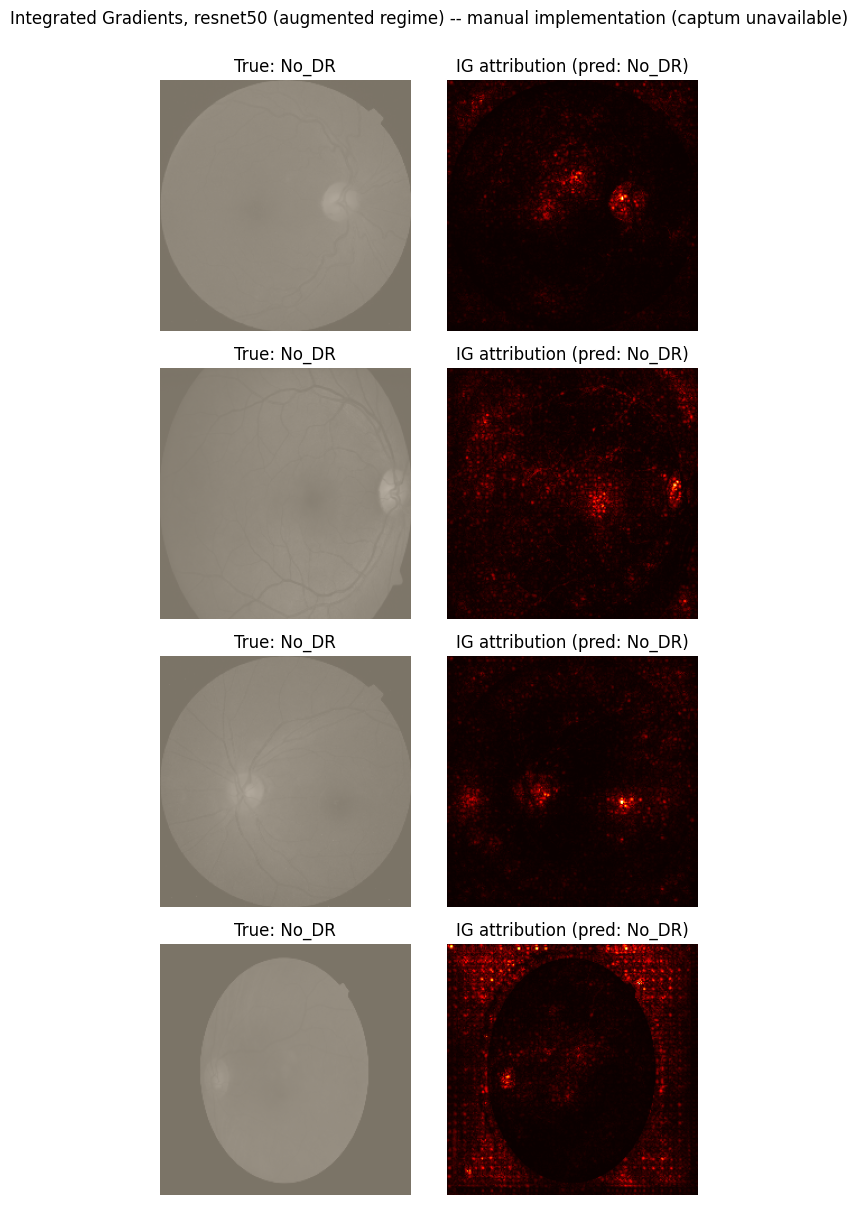

In [23]:
try:
    from captum.attr import IntegratedGradients
    HAVE_CAPTUM = True
except ImportError:
    HAVE_CAPTUM = False
    print("captum not available; using a manual Integrated Gradients implementation instead.")

def integrated_gradients(model, x, target_class, steps=32, baseline=None):
    model.eval()
    if baseline is None:
        baseline = torch.zeros_like(x)
    if HAVE_CAPTUM:
        ig = IntegratedGradients(model)
        attr = ig.attribute(x, baselines=baseline, target=target_class, n_steps=steps)
        return attr.detach().cpu()
    diff = x - baseline
    total_grad = torch.zeros_like(x)
    for alpha in torch.linspace(0.0, 1.0, steps, device=x.device):
        step_in = (baseline + alpha * diff).clone().detach().requires_grad_(True)
        out = model(step_in)
        model.zero_grad(set_to_none=True)
        out[0, target_class].backward()
        total_grad += step_in.grad
    return (diff * (total_grad / steps)).detach().cpu()

ig_model = trained_models[f"{gradcam_arch}__augmented"]
n_ig_examples = min(4, len(test_df))
fig, axes = plt.subplots(n_ig_examples, 2, figsize=(6, 3 * n_ig_examples))
if n_ig_examples == 1:
    axes = axes[None, :]
for i in range(n_ig_examples):
    item = test_ds_cam[i]
    x = item["image"].unsqueeze(0).to(DEVICE)
    raw = item["raw_image"]
    true_c = int(item["label"].item())
    with torch.no_grad():
        pred_c = int(ig_model(x).argmax(1).item())
    attr = integrated_gradients(ig_model, x, target_class=pred_c, steps=32)
    mag = attr.squeeze(0).abs().sum(0).numpy()
    if mag.max() > 0:
        mag = mag / mag.max()
    axes[i, 0].imshow(denorm_np(raw))
    axes[i, 0].set_title(f"True: {CFG.CLASS_NAMES[true_c]}"); axes[i, 0].axis("off")
    axes[i, 1].imshow(mag, cmap="hot")
    axes[i, 1].set_title(f"IG attribution (pred: {CFG.CLASS_NAMES[pred_c]})"); axes[i, 1].axis("off")
plt.suptitle(f"Integrated Gradients, {gradcam_arch} (augmented regime)" +
             ("" if HAVE_CAPTUM else " -- manual implementation (captum unavailable)"), y=1.0)
plt.tight_layout()
plt.savefig(XAI_DIR / f"integrated_gradients_{gradcam_arch}.png", dpi=250, bbox_inches="tight")
plt.show()

## 14. Final Export

Consolidates every table into a single JSON summary alongside the individual CSVs, and zips the
entire `results/` directory (tables, figures, explainability outputs, logs, and the best
checkpoint for each run) for download.

In [24]:
final_summary = {
    "dataset": DATASET_SLUG,
    "n_images_total": int(len(df_all)),
    "n_images_after_dedup": int(len(df_clean)),
    "n_exact_duplicate_groups": int(len(dup_groups)),
    "split_sizes": {"train": int(len(train_df)), "val": int(len(val_df)), "test": int(len(test_df))},
    "class_weights": {name: float(class_weights[i]) for i, name in enumerate(CFG.CLASS_NAMES)},
    "model_architectures": CFG.MODEL_NAMES,
    "regimes": CFG.REGIMES,
    "epochs_budget": CFG.EPOCHS,
    "patience": CFG.PATIENCE,
    "seed": CFG.SEED,
    "best_run": best_run_name,
    "test_results": df_results.to_dict(orient="records"),
    "bootstrap_cis": df_ci.to_dict(orient="records"),
    "ablation_results": df_ablation.to_dict(orient="records"),
    "model_parameter_counts": df_profiles.to_dict(orient="records"),
}
with open(CFG.OUTPUT_DIR / "final_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2, default=lambda o: o.item() if isinstance(o, np.generic) else str(o))

import shutil
zip_path = shutil.make_archive(str(CFG.OUTPUT_DIR.parent / "icacs_results"), "zip", root_dir=CFG.OUTPUT_DIR)
print("Final summary written to:", CFG.OUTPUT_DIR / "final_summary.json")
print("Everything zipped to:", zip_path)
print("\nDownload the zip from the Kaggle 'Output' tab after this notebook finishes running,")
print("or use it directly if running inside Kaggle's working directory.")

Final summary written to: results/final_summary.json
Everything zipped to: /content/icacs_results.zip

Download the zip from the Kaggle 'Output' tab after this notebook finishes running,
or use it directly if running inside Kaggle's working directory.
